Boosting dan Stacking – WineQT

Persiapan dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = pd.read_csv("data/WineQT.csv")
print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
# Id hanya identitas, bukan fitur prediksi
X = data.drop(columns=["quality", "Id"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)
display(y.value_counts().sort_index())

Data latih: (914, 11)
Data uji: (229, 11)


quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

Gradient Boosting

Gradient Boosting membangun pohon secara bertahap. Setiap pohon baru berusaha memperbaiki kesalahan model sebelumnya. Berikut pengamatan sederhana terhadap pengaruh jumlah pohon.

In [3]:
tree_counts = [25, 50, 100]
gb_errors = []

for n in tree_counts:
    model = GradientBoostingClassifier(
        n_estimators=n, random_state=42
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    gb_errors.append(1 - accuracy_score(y_test, pred))

gb_results = pd.DataFrame({
    "Jumlah Pohon": tree_counts,
    "Error": gb_errors
})
display(gb_results)

,Jumlah Pohon,Error
0,25,0.375546
1,50,0.366812
2,100,0.340611


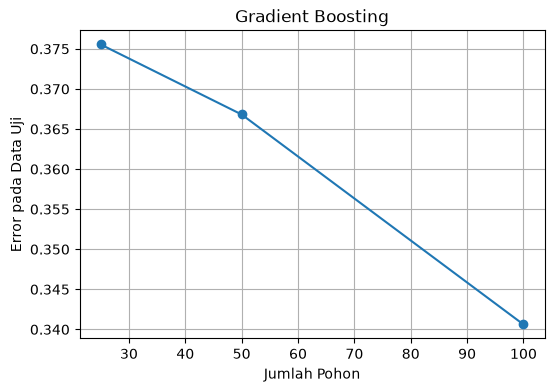

In [4]:
plt.figure(figsize=(6, 4))
plt.plot(tree_counts, gb_errors, marker="o")
plt.xlabel("Jumlah Pohon")
plt.ylabel("Error pada Data Uji")
plt.title("Gradient Boosting")
plt.grid(True)
plt.show()

Tuning Gradient Boosting dan AdaBoost

Grid Search mencoba beberapa kombinasi parameter untuk mencari model dengan skor validasi terbaik. Jumlah kombinasi dibatasi agar latihan tetap ringan.

In [5]:
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid={
        "n_estimators": [50, 100],
        "learning_rate": [0.05, 0.1]
    },
    scoring="accuracy",
    cv=3,
    n_jobs=-1
)
gb_grid.fit(X_train, y_train)

print("Parameter terbaik:", gb_grid.best_params_)
gb_model = gb_grid.best_estimator_

Parameter terbaik: {'learning_rate': 0.05, 'n_estimators': 50}


In [6]:
ada_grid = GridSearchCV(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        random_state=42
    ),
    param_grid={
        "n_estimators": [50, 100],
        "learning_rate": [0.05, 0.1]
    },
    scoring="accuracy",
    cv=3,
    n_jobs=-1
)
ada_grid.fit(X_train, y_train)

print("Parameter AdaBoost terbaik:", ada_grid.best_params_)
ada_model = ada_grid.best_estimator_

Parameter AdaBoost terbaik: {'learning_rate': 0.1, 'n_estimators': 100}


Membandingkan model boosting

In [7]:
models = {
    "Gradient Boosting": gb_model,
    "AdaBoost": ada_model
}

results = {}
for name, model in models.items():
    pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, pred)

display(pd.DataFrame.from_dict(
    results, orient="index", columns=["Accuracy"]
))

,Accuracy
Gradient Boosting,0.650655
AdaBoost,0.637555


Menggabungkan model dengan Voting Classifier

Voting Classifier menggabungkan prediksi dari beberapa model. Pada contoh ini digunakan *soft voting*, yaitu menggabungkan probabilitas prediksi. Logistic Regression menggunakan StandardScaler karena skala fitur berpengaruh terhadap model tersebut.

In [8]:
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced")
)

voting_model = VotingClassifier(
    estimators=[
        ("logistic", lr_model),
        ("gradient_boosting", gb_model),
        ("adaboost", ada_model)
    ],
    voting="soft"
)
voting_model.fit(X_train, y_train)

voting_pred = voting_model.predict(X_test)
print("Voting Accuracy:", round(accuracy_score(y_test, voting_pred), 4))
print(classification_report(y_test, voting_pred, zero_division=0))

Voting Accuracy: 0.5983
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.17      0.14      0.15         7
           5       0.72      0.77      0.75        97
           6       0.62      0.50      0.55        92
           7       0.41      0.45      0.43        29
           8       0.22      0.67      0.33         3

    accuracy                           0.60       229
   macro avg       0.36      0.42      0.37       229
weighted avg       0.61      0.60      0.60       229



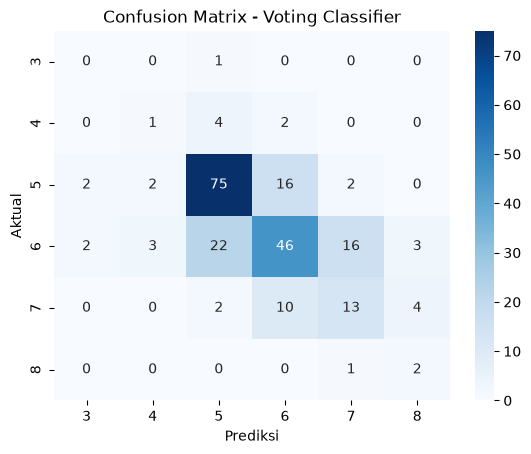

In [9]:
cm = confusion_matrix(y_test, voting_pred, labels=voting_model.classes_)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=voting_model.classes_,
    yticklabels=voting_model.classes_
)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix - Voting Classifier")
plt.show()

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.